# **Cell 1 — Load the data and prepare the forecasting inputs**

In [1]:
from pathlib import Path

import pandas as pd
from google.colab import drive

drive.mount("/content/drive")

project = Path("/content/drive/MyDrive/smartdata-dashboard")
reports_dir = project / "reports"
figure_dir = reports_dir / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

transactions = pd.read_csv(
    project / "data" / "kaggle_dataset" / "SuperMarket Analysis.csv"
)
transactions["Date"] = pd.to_datetime(
    transactions["Date"], format="%m/%d/%Y"
)

# Add up the receipts for each branch on each calendar day.
daily_sales = (
    transactions.groupby(["Date", "Branch"])["Sales"]
    .sum()
    .unstack("Branch")
    .asfreq("D")
)

# Give the model two sales clues available before the forecast day.
history = {
    "Observed": daily_sales,
    "Yesterday": daily_sales.shift(1),
    "Same weekday last week": daily_sales.shift(7),
}

forecast_data = pd.concat(
    {name: values.stack() for name, values in history.items()},
    axis=1,
).dropna().reset_index()

forecast_data["Weekday"] = forecast_data["Date"].dt.day_name()

train = forecast_data.loc[forecast_data["Date"] < "2019-02-17"]
development = forecast_data.loc[
    forecast_data["Date"].between("2019-02-17", "2019-03-09")
]
test = forecast_data.loc[
    forecast_data["Date"].between("2019-03-10", "2019-03-30")
].copy()

print(f"Training: {len(train)} branch-days")
print(f"Development: {len(development)} branch-days")
print(f"March test: {len(test)} branch-days")

Mounted at /content/drive
Training: 111 branch-days
Development: 63 branch-days
March test: 60 branch-days


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sales_inputs = ["Yesterday", "Same weekday last week"]
category_inputs = ["Branch", "Weekday"]
inputs = sales_inputs + category_inputs

preprocess = ColumnTransformer([
    ("sales", StandardScaler(), sales_inputs),
    ("categories", OneHotEncoder(handle_unknown="ignore"), category_inputs),
])

ridge_pipeline = make_pipeline(preprocess, Ridge(alpha=1.0))
ridge_pipeline.fit(train[inputs], train["Observed"])
test["Ridge regression"] = ridge_pipeline.predict(test[inputs])

methods = sales_inputs + ["Ridge regression"]
errors = test[methods].sub(test["Observed"], axis=0).abs()
positive_sales = test["Observed"].gt(0)
close = errors.loc[positive_sales].le(
    0.20 * test.loc[positive_sales, "Observed"], axis=0
)

march_summary = pd.DataFrame({
    "MAE": errors.mean(),
    "Forecasts within 20%": close.sum(),
})

print(f"March test: {len(test)} scored branch-days")
display(march_summary.round(2))

predictions = test[["Date", "Branch", "Observed", *methods]].join(
    errors.add_suffix(" absolute error")
)
predictions.to_csv(reports_dir / "final_test_predictions.csv", index=False)

# **Cell 2 — Train Ridge and save the March results**

In [2]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sales_inputs = ["Yesterday", "Same weekday last week"]
category_inputs = ["Branch", "Weekday"]
inputs = sales_inputs + category_inputs

preprocess = ColumnTransformer([
    ("sales", StandardScaler(), sales_inputs),
    ("categories", OneHotEncoder(handle_unknown="ignore"), category_inputs),
])

ridge_pipeline = make_pipeline(preprocess, Ridge(alpha=1.0))
ridge_pipeline.fit(train[inputs], train["Observed"])
test["Ridge regression"] = ridge_pipeline.predict(test[inputs])

methods = sales_inputs + ["Ridge regression"]
errors = test[methods].sub(test["Observed"], axis=0).abs()
positive_sales = test["Observed"].gt(0)
close = errors.loc[positive_sales].le(
    0.20 * test.loc[positive_sales, "Observed"], axis=0
)

march_summary = pd.DataFrame({
    "MAE": errors.mean(),
    "Forecasts within 20%": close.sum(),
})

print(f"March test: {len(test)} scored branch-days")
display(march_summary.round(2))

predictions = test[["Date", "Branch", "Observed", *methods]].join(
    errors.add_suffix(" absolute error")
)
predictions.to_csv(reports_dir / "final_test_predictions.csv", index=False)

March test: 60 scored branch-days


,MAE,Forecasts within 20%
Yesterday,829.57,9
Same weekday last week,974.81,3
Ridge regression,606.55,18


# **Cell 3 — Save the figures and download them as one ZIP**

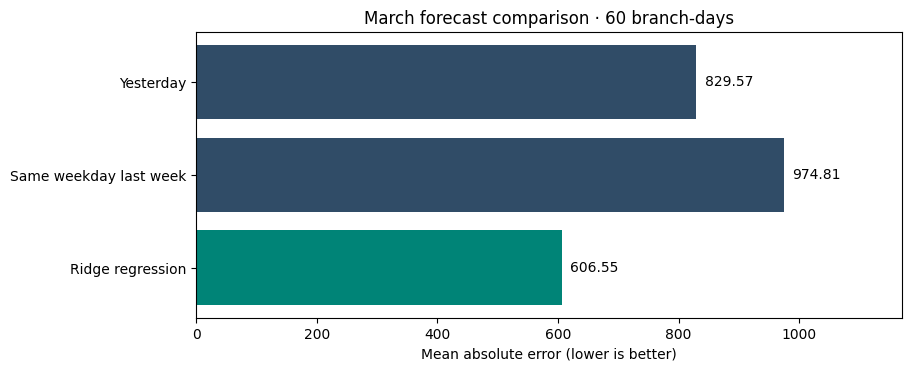

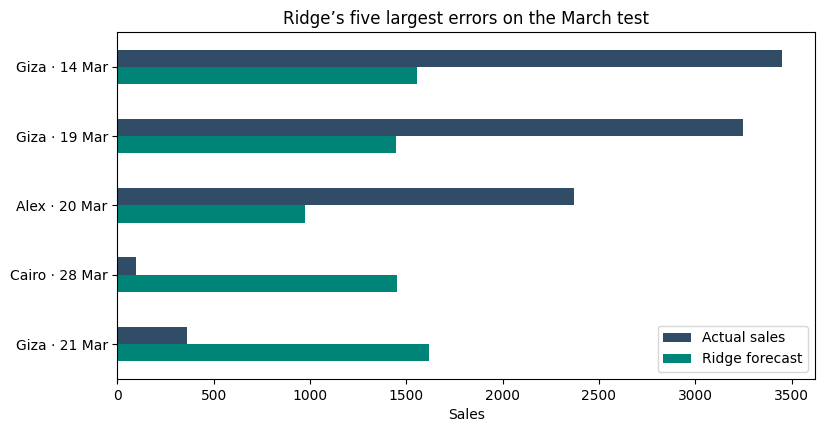

Included: final_test_mae.svg
Included: final_test_ridge_largest_errors.svg
Included: cairo_forecast_error_by_actual_sales.svg


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:
from zipfile import ZIP_DEFLATED, ZipFile

import matplotlib.pyplot as plt
from google.colab import files

# Figure 1: Compare average error on the March test.
fig, ax = plt.subplots(figsize=(9, 3.6), layout="constrained")
mae = march_summary["MAE"]
bars = ax.barh(
    mae.index, mae.values,
    color=["#304C67", "#304C67", "#008477"],
)
ax.bar_label(bars, fmt="%.2f", padding=6)
ax.invert_yaxis()
ax.set_xlim(0, mae.max() * 1.2)
ax.set_title(f"March forecast comparison · {len(test)} branch-days")
ax.set_xlabel("Mean absolute error (lower is better)")
fig.savefig(figure_dir / "final_test_mae.svg", bbox_inches="tight")
plt.show()

# Figure 2: Show actual sales and forecasts for Ridge's five largest misses.
worst = predictions.nlargest(5, "Ridge regression absolute error").copy()
worst["Branch and date"] = (
    worst["Branch"] + " · " + worst["Date"].dt.strftime("%d %b")
)

ax = worst.set_index("Branch and date")[
    ["Observed", "Ridge regression"]
].rename(columns={
    "Observed": "Actual sales",
    "Ridge regression": "Ridge forecast",
}).plot.barh(figsize=(9, 4.5), color=["#304C67", "#008477"])

ax.invert_yaxis()
ax.set_title("Ridge’s five largest errors on the March test")
ax.set_xlabel("Sales")
ax.set_ylabel("")
ax.figure.savefig(
    figure_dir / "final_test_ridge_largest_errors.svg", bbox_inches="tight"
)
plt.show()

figure_names = [
    "final_test_mae.svg",
    "final_test_ridge_largest_errors.svg",
    "cairo_forecast_error_by_actual_sales.svg",
]

zip_path = reports_dir / "SmartData_figures.zip"

with ZipFile(zip_path, "w", compression=ZIP_DEFLATED) as archive:
    for name in figure_names:
        path = figure_dir / name
        if path.is_file():
            archive.write(path, arcname=name)
            print(f"Included: {name}")
        else:
            print(f"Missing from Drive: {name}")

files.download(str(zip_path))